# Dados e Aprendizagem Automática 26/27
### Part IV

## **Logistic Regression using Titanic Dataset**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
%matplotlib inline

*Load the CSV - Titanic train*

In [2]:
train = pd.read_csv('datasets/titanic_train.csv')

**EDA**

In [3]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


**Missing Data**

<Axes: >

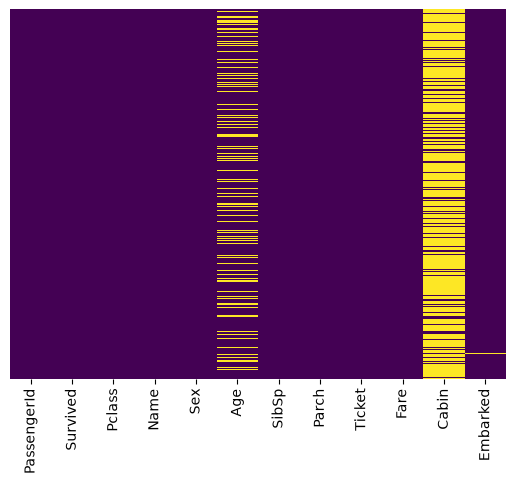

In [4]:
sns.heatmap(train.isnull(), yticklabels=False, cbar=False, cmap='viridis')

<Axes: xlabel='Survived', ylabel='count'>

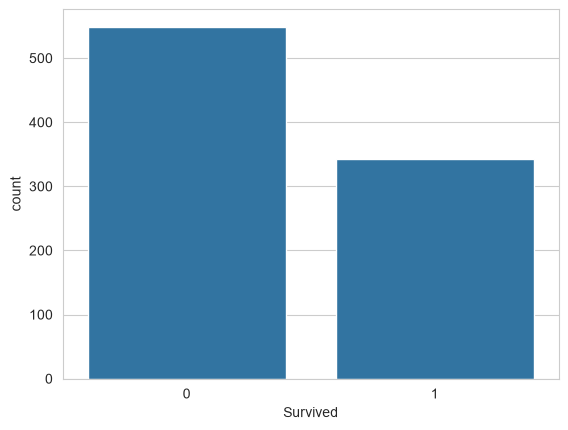

In [5]:
sns.set_style('whitegrid')
sns.countplot(x='Survived', data=train)

<Axes: xlabel='Survived', ylabel='count'>

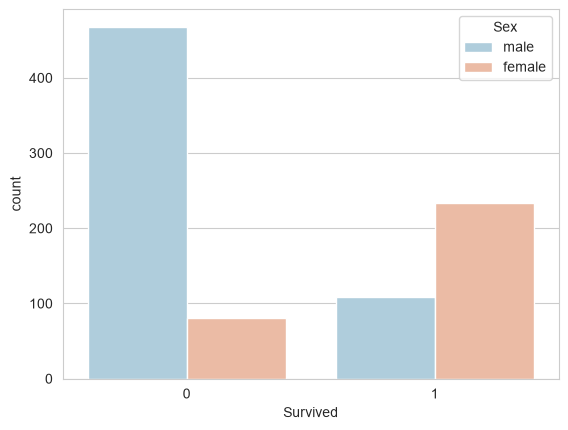

In [6]:
sns.set_style('whitegrid')
sns.countplot(x='Survived', hue='Sex', data=train, palette='RdBu_r')

<Axes: xlabel='Survived', ylabel='count'>

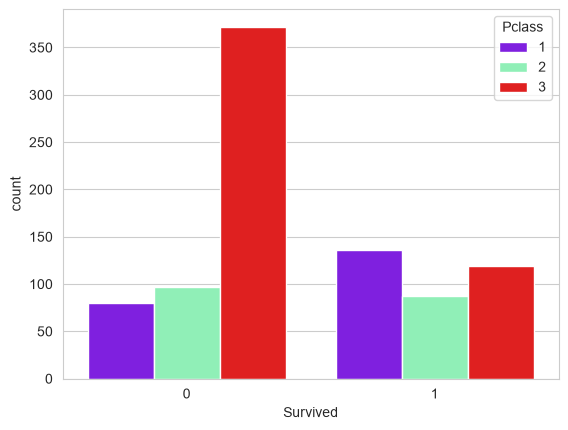

In [7]:
sns.set_style('whitegrid')
sns.countplot(x='Survived', hue='Pclass', data=train, palette='rainbow')

<Axes: xlabel='Age', ylabel='Count'>

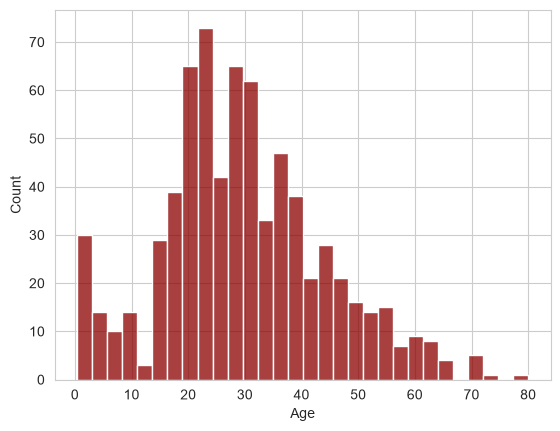

In [8]:
sns.histplot(train['Age'].dropna(), kde=False, color='darkred', bins=30)

In [ ]:
.hist(,color='darkred',alpha=0.7)

<Axes: xlabel='SibSp', ylabel='count'>

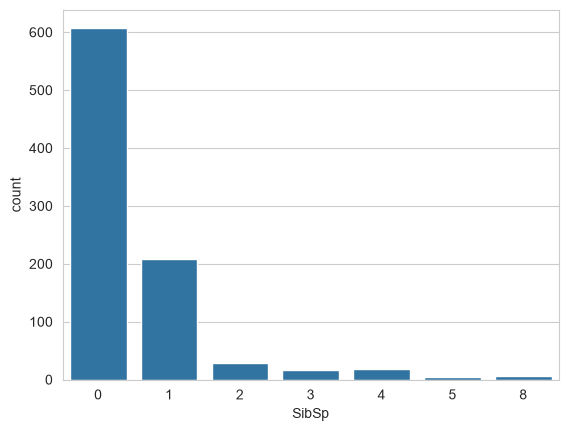

In [9]:
sns.countplot(x='SibSp', data=train)

<Axes: >

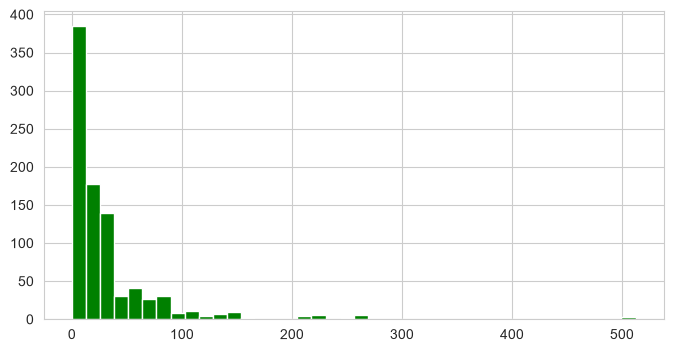

In [10]:
train['Fare'].hist(color='green', bins=40, figsize=(8,4))

**Data Cleaning**

<Axes: xlabel='Pclass', ylabel='Age'>

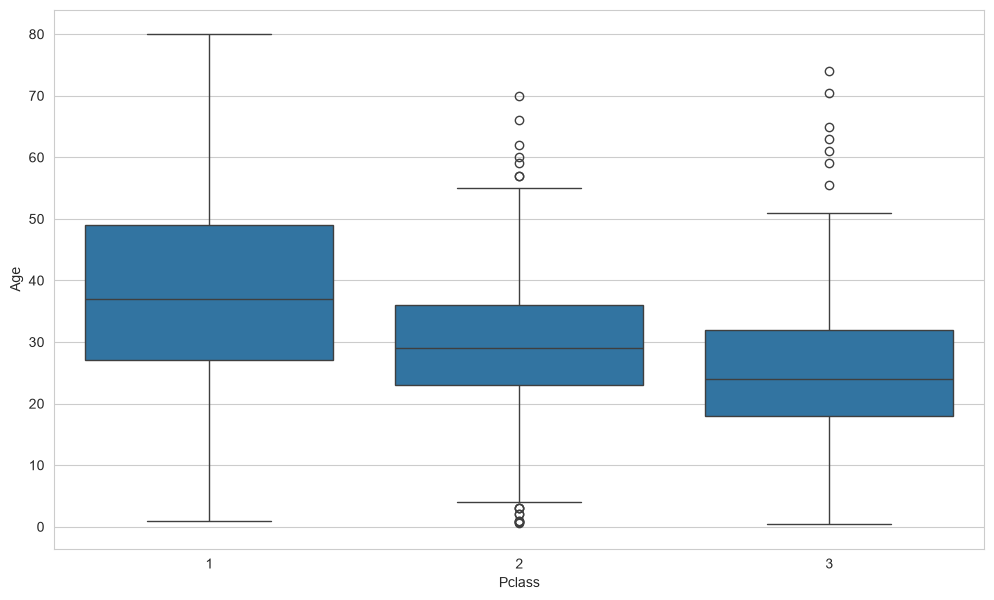

In [11]:
plt.figure(figsize=(12, 7))
sns.boxplot(x='Pclass', y='Age', data=train)

In [12]:
train['Age'] = train['Age'].fillna(train.groupby('Pclass')['Age'].transform('median'))

<Axes: >

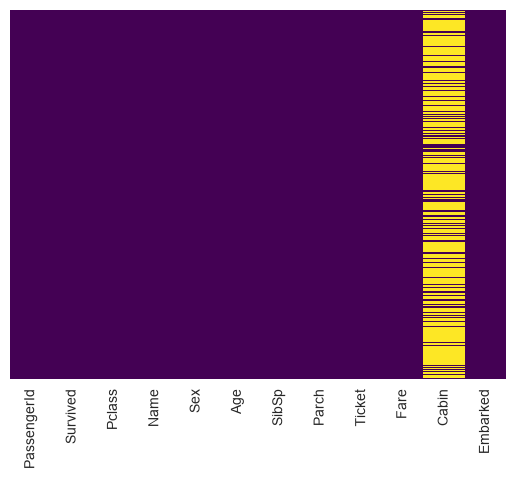

In [13]:
sns.heatmap(train.isnull(), yticklabels=False,cbar=False,cmap='viridis')

Drop the <code>Cabin</code> column and the row in <code>Embarked</code> that is *NaN*:

In [14]:
train.drop('Cabin',axis=1,inplace=True)

In [15]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


In [16]:
train.dropna(inplace=True)

In [17]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,889.000000,889.000000,889.000000,889.000000,889.000000,889.000000,889.000000
mean,446.000000,0.382452,2.311586,29.019314,0.524184,0.382452,32.096681
std,256.998173,0.486260,0.834700,13.209814,1.103705,0.806761,49.697504
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,224.000000,0.000000,2.000000,22.000000,0.000000,0.000000,7.895800
50%,446.000000,0.000000,3.000000,26.000000,0.000000,0.000000,14.454200
75%,668.000000,1.000000,3.000000,36.500000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


**Converting Categorical Features**

In [18]:
train.info()

<class 'pandas.DataFrame'>
Index: 889 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  889 non-null    int64  
 1   Survived     889 non-null    int64  
 2   Pclass       889 non-null    int64  
 3   Name         889 non-null    str    
 4   Sex          889 non-null    str    
 5   Age          889 non-null    float64
 6   SibSp        889 non-null    int64  
 7   Parch        889 non-null    int64  
 8   Ticket       889 non-null    str    
 9   Fare         889 non-null    float64
 10  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(4)
memory usage: 83.3 KB


In [19]:
sex = pd.get_dummies(train['Sex'],drop_first=True)
embark = pd.get_dummies(train['Embarked'],drop_first=True)

In [20]:
train.drop(['Sex', 'Embarked', 'Name', 'Ticket'],axis=1,inplace=True)

In [21]:
train = pd.concat([train, sex, embark], axis=1)

In [22]:
train.head()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,male,Q,S
0,1,0,3,22.0,1,0,7.2500,True,False,True
1,2,1,1,38.0,1,0,71.2833,False,False,False
2,3,1,3,26.0,0,0,7.9250,False,False,True
3,4,1,1,35.0,1,0,53.1000,False,False,True
4,5,0,3,35.0,0,0,8.0500,True,False,True


**Logistic Regression Model**

In [23]:
from sklearn.model_selection import train_test_split
X = train.drop('Survived',axis=1)
y = train['Survived']

In [24]:
X_train, X_test, y_train, y_test = train_test_split( X, y,
                                                    test_size=0.3, 
                                                    random_state=101)

<Axes: xlabel='Survived', ylabel='count'>

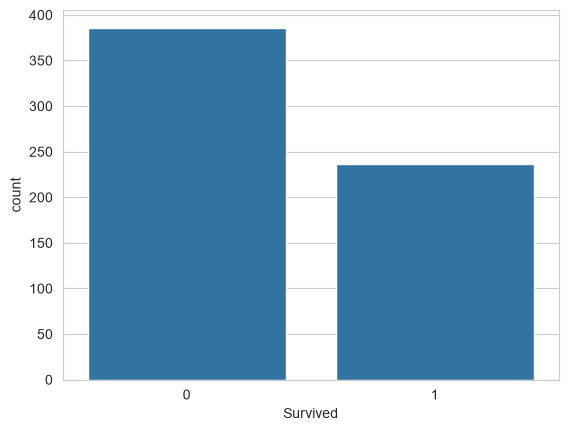

In [25]:
sns.set_style('whitegrid')
sns.countplot(x='Survived', data = pd.DataFrame(y_train,columns=['Survived']) )

<Axes: xlabel='Survived', ylabel='count'>

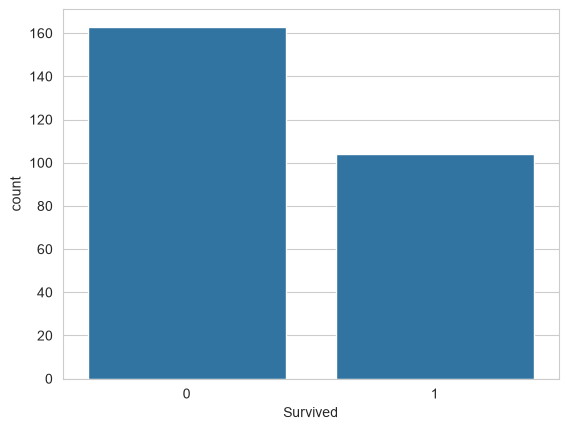

In [26]:
sns.set_style('whitegrid')
sns.countplot(x='Survived', data = pd.DataFrame(y_test,columns=['Survived']) )

<code>sklearn.linear_model.LogisticRegression(penalty='l2', *, dual=False, tol=0.0001, C=1.0, fit_intercept=True, intercept_scaling=1, class_weight=None, random_state=None, solver='lbfgs', max_iter=100, multi_class='deprecated', verbose=0, warm_start=False, n_jobs=None, l1_ratio=None)</code>

LogisticRegression' **solvers**:

- Small datasets, ‘liblinear’ is a good choice, whereas ‘sag’ and ‘saga’ are faster for large ones
- Multiclass problems, only ‘newton-cg’, ‘sag’, ‘saga’ and ‘lbfgs’ handle multinomial loss
- ‘liblinear’ is limited to one-versus-rest schemes.

Supported **penalties** by solver:

- ‘newton-cg’ - [‘l2’, ‘none’]

- ‘lbfgs’ - [‘l2’, ‘none’]

- ‘liblinear’ - [‘l1’, ‘l2’]

- ‘sag’ - [‘l2’, ‘none’]

- ‘saga’ - [‘elasticnet’, ‘l1’, ‘l2’, ‘none’]

In [27]:
from sklearn.linear_model import LogisticRegression

**logmodel1 - LogisticRegression(random_state=2022, solver='newton-cg')**

In [28]:
starttime = time.process_time()

logmodel1 = LogisticRegression(random_state=2022, solver='newton-cg')
print(logmodel1)
logmodel1.fit(X_train, y_train)

endtime = time.process_time()
print(f"Time spent: {endtime - starttime} seconds")

LogisticRegression(random_state=2022, solver='newton-cg')
Time spent: 0.02829199999999954 seconds


In [29]:
predictions1 = logmodel1.predict(X_test)

**logmodel2 - LogisticRegression(random_state=2022, solver='lbfgs')**

In [30]:
starttime = time.process_time()

logmodel2 = LogisticRegression(random_state=2022, solver='lbfgs', max_iter=800)
print(logmodel2)
logmodel2.fit(X_train, y_train)

endtime = time.process_time()
print(f"Time spent: {endtime - starttime} seconds")

LogisticRegression(max_iter=800, random_state=2022)
Time spent: 0.8662599999999996 seconds


In [31]:
predictions2 = logmodel2.predict(X_test)

**logmodel3 - LogisticRegression(random_state=2022, solver='liblinear')**

In [32]:
starttime = time.process_time()

logmodel3 = LogisticRegression(random_state=2022, solver='liblinear' )
print(logmodel3)
logmodel3.fit(X_train, y_train)

endtime = time.process_time()
print(f"Time spent: {endtime - starttime} seconds")

LogisticRegression(random_state=2022, solver='liblinear')
Time spent: 0.010640999999999678 seconds


In [33]:
predictions3 = logmodel3.predict(X_test)

**Evaluation**

In [34]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

In [35]:
print("With 'newton-cg': \n", classification_report(y_test, predictions1))
print("With 'lbfgs': \n", classification_report(y_test, predictions2))
print("With 'liblinear': \n", classification_report(y_test, predictions3))

With 'newton-cg': 
               precision    recall  f1-score   support

           0       0.82      0.91      0.86       163
           1       0.84      0.68      0.75       104

    accuracy                           0.82       267
   macro avg       0.83      0.80      0.81       267
weighted avg       0.83      0.82      0.82       267

With 'lbfgs': 
               precision    recall  f1-score   support

           0       0.82      0.91      0.86       163
           1       0.84      0.68      0.75       104

    accuracy                           0.82       267
   macro avg       0.83      0.80      0.81       267
weighted avg       0.83      0.82      0.82       267

With 'liblinear': 
               precision    recall  f1-score   support

           0       0.81      0.93      0.86       163
           1       0.85      0.65      0.74       104

    accuracy                           0.82       267
   macro avg       0.83      0.79      0.80       267
weighted avg      

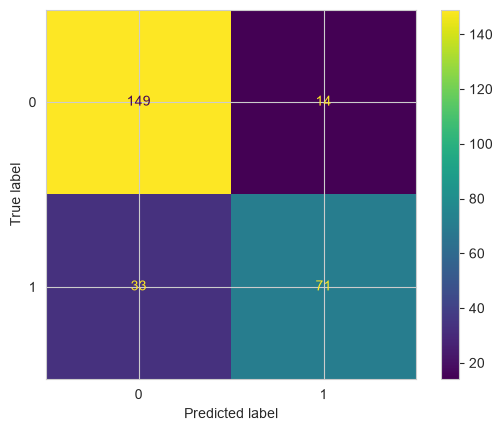

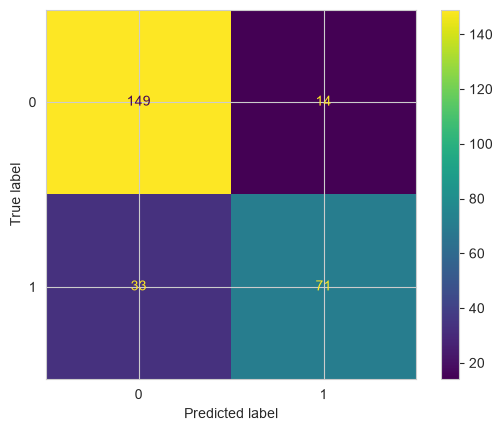

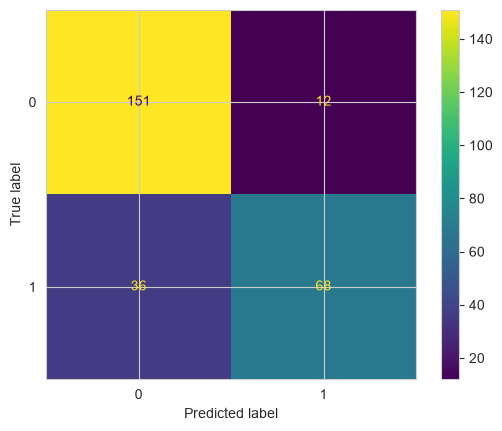

In [36]:
ConfusionMatrixDisplay.from_predictions(y_test, predictions1)
ConfusionMatrixDisplay.from_predictions(y_test, predictions2)
ConfusionMatrixDisplay.from_predictions(y_test, predictions3)

Not so bad! You might want to explore other feature engineering and the other titanic_text.csv file, some suggestions for feature engineering:

* Try grabbing the Title (Dr.,Mr.,Mrs,etc..) from the name as a feature
* Maybe the Cabin letter could be a feature
* Is there any info you can get from the ticket?